In [572]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
# from tensorflow.keras import models , layers, regularizers
# from tensorflow.keras.callbacks import TensorBoard
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.manifold import TSNE
import yfinance as yf
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [573]:
# tickers = ['BTC-USD','ETH-USD','^GSPC','^IXIC','^VIX','DX-Y.NYB','^TNX','GC=F','MSTR',]
# raw = yf.download(tickers, start='2018-01-01')['Close']
#
# # تقویم مبنا = روزهای BTC
# btc_idx = raw['BTC-USD'].dropna().index
# df = raw.reindex(btc_idx)
#
# # پر کردن آخر هفته‌ها با آخرین مقدار قبلی (محدود به ۴ روز)
# df = df.ffill(limit=4)
#
# df.to_csv("full_data.csv")

In [574]:
# df = yf.download("DOGE-USD", start='2018-01-01', end='2026-09-17')
# df.to_csv("DOGE-USD.csv")

In [575]:
df_btc = pd.read_csv("BTC-USD.csv")
df_eth = pd.read_csv("ETH-USD.csv")
df_xrp = pd.read_csv("XRP-USD.csv")
df_bch = pd.read_csv("BCH-USD.csv")

df_bnb = pd.read_csv("BNB-USD.csv")
df_ltc = pd.read_csv("LTC-USD.csv")
df_doge = pd.read_csv("DOGE-USD.csv")
# df = pd.read_csv("full_data.csv")

In [576]:
# btc_scaler = StandardScaler()
# df['Close'] = btc_scaler.fit_transform(df['Close'].to_numpy().reshape(-1, 1))

In [577]:
# df.drop("Date", axis=1, inplace=True)
df_btc.drop("Date", axis=1, inplace=True)
df_eth.drop("Date", axis=1, inplace=True)
df_xrp.drop("Date", axis=1, inplace=True)
df_bch.drop("Date", axis=1, inplace=True)

df_bnb.drop("Date", axis=1, inplace=True)
df_ltc.drop("Date", axis=1, inplace=True)
df_doge.drop("Date", axis=1, inplace=True)

In [578]:
df_btc.columns = ['close_btc', 'high_btc', 'low_btc', 'open_btc', 'volume_btc']
df_eth.columns = ['close_eth', 'high_eth', 'low_eth', 'open_eth', 'volume_eth']
df_xrp.columns = ['close_xrp', 'high_xrp', 'low_xrp', 'open_xrp', 'volume_xrp']
df_bch.columns = ['close_bch', 'high_bch', 'low_bch', 'open_bch', 'volume_bch']

df_bnb.columns = ['close_bnb', 'high_bnb', 'low_bnb', 'open_bnb', 'volume_bnb']
df_ltc.columns = ['close_ltc', 'high_ltc', 'low_ltc', 'open_ltc', 'volume_ltc']
df_doge.columns = ['close_doge', 'high_doge', 'low_doge', 'open_doge', 'volume_doge']

In [579]:
df = pd.DataFrame(np.c_[df_btc, df_eth, df_xrp, df_bch, df_bnb, df_ltc, df_doge])

In [580]:
df.columns = ['close_btc','high_btc','low_btc','open_btc','volume_btc', 'close_eth','high_eth','low_eth','open_eth','volume_eth', 'close_xrp', 'high_xrp', 'low_xrp', 'open_xrp', 'volume_xrp', 'close_bch', 'high_bch', 'low_bch', 'open_bch', 'volume_bch',
              'close_bnb', 'high_bnb', 'low_bnb', 'open_bnb', 'volume_bnb',
              'close_ltc', 'high_ltc', 'low_ltc', 'open_ltc', 'volume_ltc',
              'close_doge', 'high_doge', 'low_doge', 'open_doge', 'volume_doge']

In [581]:
df['tomorrows_profit_btc'] = df['close_btc'] - df['open_btc']

In [582]:
# df['btc_open'] = df['BTC-USD'].shift(1)
# df.dropna(inplace=True)
# df['tomorrows_profit_btc'] =  df['btc_open'] - df['BTC-USD']

In [583]:
df.loc[df['tomorrows_profit_btc'] > 0, 'tomorrows_profit_btc'] = 1
df.loc[df['tomorrows_profit_btc'] <= 0, 'tomorrows_profit_btc'] = 0

In [584]:
df['tomorrows_profit_btc'] = df['tomorrows_profit_btc'].shift(-1)

In [585]:
df

,close_btc,high_btc,low_btc,open_btc,volume_btc,close_eth,high_eth,low_eth,open_eth,volume_eth,...,high_ltc,low_ltc,open_ltc,volume_ltc,close_doge,high_doge,low_doge,open_doge,volume_doge,tomorrows_profit_btc
0,13657.200195,14112.200195,13154.700195,14112.200195,1.029120e+10,772.640991,782.530029,742.004028,755.757019,2.595760e+09,...,236.634003,222.203003,231.666000,6.331420e+08,0.008909,0.009063,0.008101,0.009031,50616900.0,1.0
1,14982.099609,15444.599609,13163.599609,13625.000000,1.684660e+10,884.443970,914.830017,772.346008,772.346008,5.783350e+09,...,263.625000,228.990005,228.990005,1.237950e+09,0.009145,0.009598,0.008551,0.008873,89424096.0,1.0
2,15201.000000,15572.799805,14844.500000,14978.200195,1.687190e+10,962.719971,974.471008,868.450989,886.000000,5.093160e+09,...,260.742004,243.134995,255.695007,3.215280e+09,0.009320,0.009584,0.008882,0.009088,66349900.0,1.0
3,15599.200195,15739.700195,14522.200195,15270.700195,2.178320e+10,980.921997,1045.079956,946.085999,961.713013,6.502860e+09,...,245.475006,227.013000,245.475006,3.481550e+09,0.009644,0.010036,0.008768,0.009346,108986000.0,1.0
4,17429.500000,17705.199219,15202.799805,15477.200195,2.384090e+10,997.719971,1075.390015,956.325012,975.750000,6.683150e+09,...,256.148010,237.880005,241.033997,1.710600e+09,0.012167,0.012283,0.009589,0.009660,212383008.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3176,77270.468750,77479.656250,77045.000000,77175.070312,1.266477e+10,2525.944580,2544.472412,2508.801514,2514.770020,8.012826e+09,...,54.220402,53.185513,53.266029,1.270578e+08,0.084853,0.085264,0.084152,0.084286,346142564.0,0.0
3177,76838.156250,77415.656250,76498.382812,77270.179688,1.360787e+10,2477.020752,2526.853760,2462.839600,2525.942383,9.643848e+09,...,55.129993,53.326374,53.638454,1.953808e+08,0.082421,0.085128,0.082202,0.084853,417755598.0,1.0
3178,78163.382812,79568.953125,76367.375000,76830.281250,2.990936e+10,2514.406982,2612.403320,2465.426514,2476.603027,1.600958e+10,...,54.539680,53.118057,53.735054,2.111737e+08,0.083632,0.085954,0.082081,0.082421,746197216.0,0.0
3179,75612.507812,78242.546875,74944.593750,78162.484375,3.969468e+10,2399.086914,2519.318848,2357.959229,2514.361816,2.027524e+10,...,53.129398,50.862846,53.121029,2.440270e+08,0.080076,0.083881,0.079016,0.083632,983582349.0,1.0


In [586]:
# df.value_counts()

In [587]:
# X = df[["BTC-USD","DX-Y.NYB","ETH-USD","GC=F","MSTR","^GSPC","^IXIC","^TNX","^VIX"]]
X = df[['close_btc','high_btc','low_btc','open_btc','volume_btc', 'close_eth','high_eth','low_eth','open_eth','volume_eth', 'close_xrp', 'high_xrp', 'low_xrp', 'open_xrp', 'volume_xrp', 'close_bch', 'high_bch', 'low_bch', 'open_bch', 'volume_bch',
              'close_bnb', 'high_bnb', 'low_bnb', 'open_bnb', 'volume_bnb',
              'close_ltc', 'high_ltc', 'low_ltc', 'open_ltc', 'volume_ltc',
              'close_doge', 'high_doge', 'low_doge', 'open_doge', 'volume_doge']]
y = df[['tomorrows_profit_btc']]

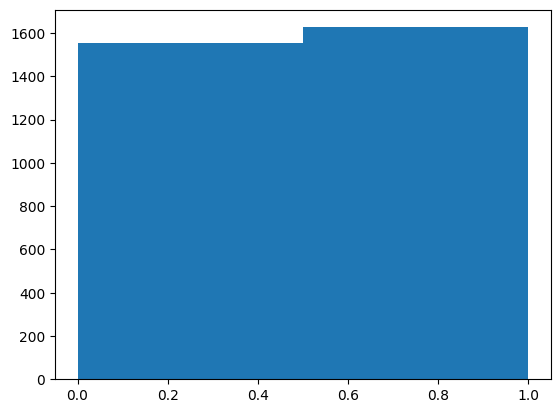

In [588]:
plt.hist(y, bins=2)

In [589]:
tsne = TSNE(
    #n_jobs=-1,
    n_components=3,
)
X = tsne.fit_transform(X)

In [590]:
lastData = X[[-1]]
X = X[:-2]
y = y[:-2]
# y.dropna(inplace=True)

In [591]:
lastData

array([[ 1.1709999,  3.4447355, -7.2936206]], dtype=float32)

In [592]:
# np.cumsum(tsne.explained_variance_ratio_)


In [593]:
x_train, x_test, y_train, y_test = train_test_split(X, y, train_size=0.95, shuffle=False)

In [594]:
model = MLPClassifier(
    hidden_layer_sizes = (128,256,256,256,128,64,32),
    activation = "relu",
    solver= "adam",
    alpha = 0.1,
    batch_size = "auto",
    learning_rate_init = 0.00001,
    max_iter = 10000,
    tol = 1e-5,
    verbose = 10,
)

In [595]:
# model = models.Sequential([
#     layers.Input(shape=(20,)),
#     layers.BatchNormalization(),
#     layers.Dense(20, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(50, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(100, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(100, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(200, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(200, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(200, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(100, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(100, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(50, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(5, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
#     layers.Dense(1, activation='sigmoid'),
# ])

In [596]:
# tensorboard = TensorBoard(
#     log_dir='./logs',
#     histogram_freq=1,
# )

In [597]:
# model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"], )

In [598]:
# model.fit(x_train, y_train, callbacks=[tensorboard], epochs=100, validation_split=0.1)

In [599]:
# model.fit(x_train, y_train)

In [600]:
c_v = cross_validate(
    estimator=model,
    X=x_train,
    y=y_train,
    scoring="recall",
    cv=3,
    return_train_score=True,
    verbose=10,
    n_jobs=-1,
    #return_indices=True,
    return_estimator=True,
)

[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:  5.5min finished


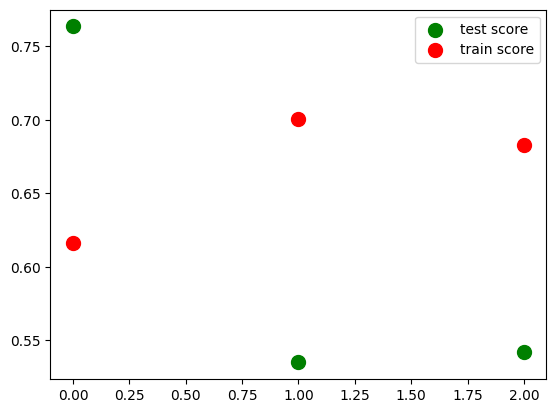

In [601]:
plt.scatter(np.arange(3),c_v['test_score'], s=100, color='green', label='test score')
plt.scatter(np.arange(3),c_v['train_score'], s=100, color='red', label='train score')
plt.legend()

In [608]:
model = c_v['estimator'][1]

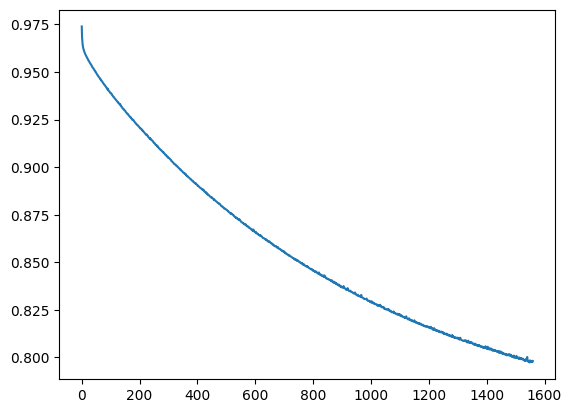

In [609]:
plt.plot(model.loss_curve_)

In [610]:
y_pred = model.predict(x_train)
print(classification_report(y_train, y_pred))

              precision    recall  f1-score   support

         0.0       0.56      0.47      0.51      1473
         1.0       0.56      0.65      0.60      1547

    accuracy                           0.56      3020
   macro avg       0.56      0.56      0.56      3020
weighted avg       0.56      0.56      0.56      3020



In [611]:
y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.57      0.42      0.49        80
         1.0       0.54      0.67      0.60        79

    accuracy                           0.55       159
   macro avg       0.55      0.55      0.54       159
weighted avg       0.55      0.55      0.54       159



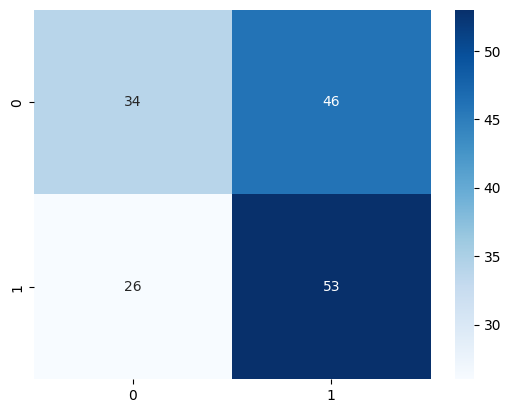

In [613]:
sns.heatmap(confusion_matrix(y_test, y_pred), cmap="Blues", annot=True, fmt="g")

In [616]:
lastData

array([[ 1.1709999,  3.4447355, -7.2936206]], dtype=float32)

In [617]:
model.predict(lastData)

array([1.])